# Part 2: Question 1, Predicting a Plant's Primary Fuel

**Data science project: The Global Energy Transition Through Power Plants**

**Name:** Bernard Issifu

**Question 1.** Can a power plant's primary fuel be predicted from its capacity, location and
commissioning year?

This notebook uses the prepared data from Part 1 (run `01_data_preparation_eda.ipynb` first). The R
version is `r/02_q1_classification.Rmd`.

In [1]:
# ---- Setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupKFold,
                                     cross_val_score)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

sns.set_theme(style="whitegrid")
FIG_DIR = "../report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv("../data/processed/power_plants_clean_python.csv")
print(df.shape)
df["fuel"].value_counts().to_frame("plants")

(34936, 15)


,plants
fuel,
Solar,10665
Hydro,7156
Wind,5344
Gas,3998
Other,3123
Coal,2330
Oil,2320


---
# 1. Approach

**Why it matters.** Many energy datasets, especially in lower-income countries, list plants with a
location and capacity but an incomplete or unreliable fuel. A model that infers the fuel from basic
plant attributes could help fill such gaps and check existing records.

**Target.** Seven fuel groups: Solar, Hydro, Wind, Gas, Coal, Oil and Other (biomass, waste, nuclear,
geothermal and smaller categories). The classes are unequal (Solar 10,665 plants, Oil 2,320), so the
models weight classes equally and the main metric is **macro-F1**, the average F1 score across the seven
classes, which treats a small class as important as a large one. Accuracy and per-class recall are
also reported.

**Features (main model).** Six plant attributes: log10 capacity, latitude, longitude, commissioning
year (median-filled), a flag for a missing commissioning year, and whether a secondary fuel is listed.

**Leakage check.** The database also provides WRI's *estimated* generation, from which a capacity
factor can be computed. WRI estimates generation using the fuel type, so this feature partly encodes the
answer. It is excluded from the main models and added only in a separate comparison.

**Models.** Multinomial **logistic regression** (standardized features) as a linear baseline; a
**decision tree** (depth 8, at least 20 plants per leaf); and a **random forest** (300 trees).

**Validation.** An 80/20 split stratified on fuel, plus two kinds of 5-fold cross-validation on all the
data: ordinary stratified folds, and **folds grouped by country**, where every plant of a country is in
the same fold. The grouped version tests whether the models work for countries they have never seen.

In [2]:
features = ["log_capacity", "latitude", "longitude", "comm_year", "year_missing", "multi_fuel"]
X = df[features]
y = df["fuel"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Training: {len(X_train):,} plants   Test: {len(X_test):,} plants")

def make_models():
    return {
        "Logistic regression": Pipeline([("scale", StandardScaler()),
                                         ("model", LogisticRegression(max_iter=3000,
                                                                      class_weight="balanced"))]),
        "Decision tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20,
                                                class_weight="balanced", random_state=42),
        "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                class_weight="balanced_subsample", n_jobs=2,
                                                random_state=42),
    }

Training: 27,948 plants   Test: 6,988 plants


---
# 2. Training and evaluation

In [3]:
strat_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
group_cv = GroupKFold(n_splits=5)

rows, fitted, preds = [], {}, {}
for name, model in make_models().items():
    cv_strat = cross_val_score(model, X, y, cv=strat_cv, scoring="f1_macro")
    cv_group = cross_val_score(model, X, y, cv=group_cv, groups=df["country"], scoring="f1_macro")
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    fitted[name], preds[name] = model, p
    rows.append({"model": name,
                 "Test accuracy": accuracy_score(y_test, p),
                 "Test macro-F1": f1_score(y_test, p, average="macro"),
                 "CV macro-F1 (random folds)": f"{cv_strat.mean():.3f} ± {cv_strat.std():.3f}",
                 "CV macro-F1 (country folds)": f"{cv_group.mean():.3f} ± {cv_group.std():.3f}"})

results = pd.DataFrame(rows).set_index("model").round(3)
results

,Test accuracy,Test macro-F1,CV macro-F1 (random folds),CV macro-F1 (country folds)
model,,,,
Logistic regression,0.480,0.412,0.418 ± 0.006,0.282 ± 0.026
Decision tree,0.550,0.525,0.538 ± 0.007,0.279 ± 0.064
Random forest,0.782,0.739,0.729 ± 0.004,0.332 ± 0.035


In [4]:
# Recall for each fuel on the test set
classes = sorted(y.unique())
recall_table = pd.DataFrame({name: recall_score(y_test, p, labels=classes, average=None)
                             for name, p in preds.items()}, index=classes).round(3)
recall_table

,Logistic regression,Decision tree,Random forest
Coal,0.648,0.691,0.770
Gas,0.381,0.440,0.634
Hydro,0.275,0.409,0.796
Oil,0.392,0.644,0.672
Other,0.155,0.446,0.579
Solar,0.757,0.596,0.891
Wind,0.429,0.690,0.827


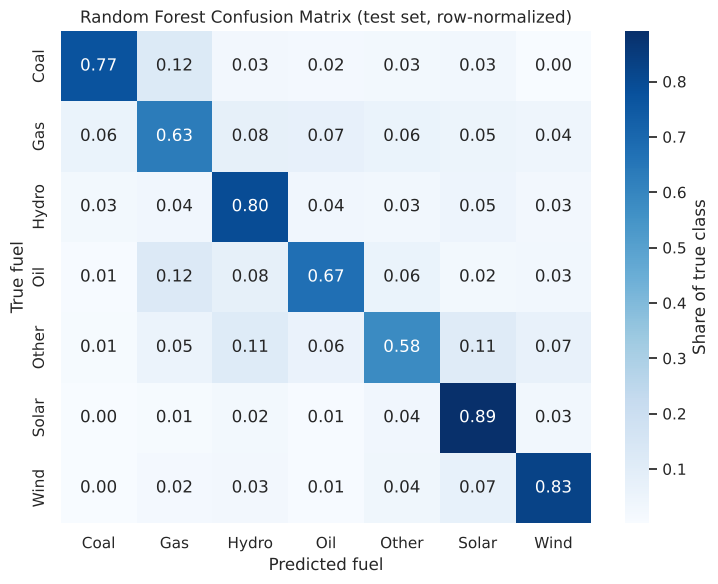

In [5]:
# Random forest confusion matrix, as the share of each true fuel predicted as each fuel
cm = confusion_matrix(y_test, preds["Random forest"], labels=classes, normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes,
            cbar_kws={"label": "Share of true class"}, ax=ax)
ax.set_title("Random Forest Confusion Matrix (test set, row-normalized)")
ax.set_xlabel("Predicted fuel")
ax.set_ylabel("True fuel")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_confusion_matrix.png", dpi=150)
plt.show()

**Interpretation.** On a random test split the **random forest is far ahead**: accuracy 0.782 and
macro-F1 0.739, against 0.550 / 0.525 for the decision tree and 0.480 / 0.412 for logistic regression,
and the random-fold cross-validation gives almost the same figures (0.729 for the forest). It
recognizes solar (recall 0.891), wind (0.827), hydro (0.796) and coal (0.770) best. Its main confusions
are between the thermal fuels: 12.5% of oil plants and 12.2% of coal plants are predicted as gas, and
the mixed 'Other' group is often mistaken for hydro (11.4%) or solar (11.0%). Logistic regression does
poorly because fuel does not change in a straight line with latitude, longitude or capacity.

The **country-grouped cross-validation tells a different story**: when every plant of a country is
held out together, the forest's macro-F1 falls from 0.729 to **0.332** (0.28 for the other two models).
On a random split, many test plants have near neighbours of the same fuel in the training set (a solar
farm next to other solar farms, hydro plants along the same river), and the forest exploits this
location memory. It does not transfer well to a country it has never seen.

---
# 3. Leakage check: adding the estimated capacity factor

In [6]:
X_cf = df[features + ["capacity_factor_est"]].copy()
X_cf["capacity_factor_est"] = X_cf["capacity_factor_est"].fillna(X_cf["capacity_factor_est"].median())
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_cf, y, test_size=0.2, stratify=y,
                                                        random_state=42)
leak_rows = []
for name, model in make_models().items():
    model.fit(Xc_train, yc_train)
    p = model.predict(Xc_test)
    leak_rows.append({"model": name,
                      "Macro-F1 without capacity factor": results.loc[name, "Test macro-F1"],
                      "Macro-F1 with capacity factor": round(f1_score(yc_test, p, average="macro"), 3)})
leak = pd.DataFrame(leak_rows).set_index("model")
leak

,Macro-F1 without capacity factor,Macro-F1 with capacity factor
model,,
Logistic regression,0.412,0.525
Decision tree,0.525,0.828
Random forest,0.739,0.965


In [7]:
# Estimated capacity factor by fuel: nearly constant within some fuels, which is the leak
df.groupby("fuel")["capacity_factor_est"].describe()[["mean", "std", "25%", "50%", "75%"]].round(3)

,mean,std,25%,50%,75%
fuel,,,,,
Coal,0.557,0.105,0.527,0.556,0.601
Gas,0.449,0.127,0.402,0.403,0.499
Hydro,0.376,0.097,0.315,0.380,0.439
Oil,0.177,0.133,0.067,0.191,0.225
Other,0.250,0.316,0.021,0.110,0.481
Solar,0.195,0.035,0.172,0.186,0.211
Wind,0.279,0.075,0.212,0.278,0.321


**Interpretation.** Adding WRI's estimated capacity factor lifts the random forest's macro-F1 from
0.739 to **0.965** and the decision tree's from 0.525 to 0.828. That jump is a warning sign rather than
a success: WRI estimated generation from the fuel type, so the capacity factor is nearly fixed within
some fuels (solar's interquartile range is only 0.172–0.211, and half of gas plants sit at about 0.40).
A model using it is largely reading the fuel back out of a number built from the fuel. The main models
therefore leave it out.

---
# 4. Which features matter?

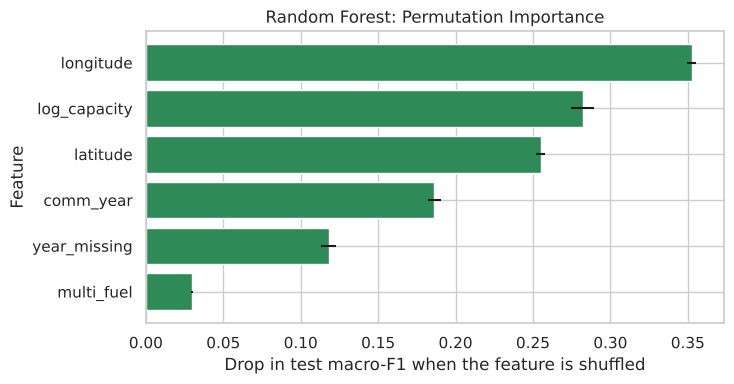

,mean_f1_drop,sd
longitude,0.3524,0.0032
log_capacity,0.2821,0.0075
latitude,0.2549,0.0028
comm_year,0.1864,0.0043
year_missing,0.1181,0.0050
multi_fuel,0.0297,0.0007


In [8]:
rf = fitted["Random forest"]
perm = permutation_importance(rf, X_test, y_test, scoring="f1_macro", n_repeats=5,
                              random_state=42, n_jobs=2)
imp = pd.DataFrame({"mean_f1_drop": perm.importances_mean, "sd": perm.importances_std},
                   index=features).sort_values("mean_f1_drop", ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(imp.index[::-1], imp["mean_f1_drop"][::-1], xerr=imp["sd"][::-1], color="seagreen")
ax.set_title("Random Forest: Permutation Importance")
ax.set_xlabel("Drop in test macro-F1 when the feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_permutation_importance.png", dpi=150)
plt.show()
imp.round(4)

In [9]:
# Top of the decision tree (log_capacity is log10 MW; year_missing is 0/1)
print(export_text(fitted["Decision tree"], feature_names=features, max_depth=2))

|--- log_capacity <= 2.21
|   |--- comm_year <= 2005.95
|   |   |--- comm_year <= 1963.04
|   |   |   |--- truncated branch of depth 6
|   |   |--- comm_year >  1963.04
|   |   |   |--- truncated branch of depth 6
|   |--- comm_year >  2005.95
|   |   |--- latitude <= 12.86
|   |   |   |--- truncated branch of depth 6
|   |   |--- latitude >  12.86
|   |   |   |--- truncated branch of depth 6
|--- log_capacity >  2.21
|   |--- longitude <= 73.18
|   |   |--- comm_year <= 1992.01
|   |   |   |--- truncated branch of depth 6
|   |   |--- comm_year >  1992.01
|   |   |   |--- truncated branch of depth 6
|   |--- longitude >  73.18
|   |   |--- year_missing <= 0.50
|   |   |   |--- truncated branch of depth 6
|   |   |--- year_missing >  0.50
|   |   |   |--- truncated branch of depth 6



In [10]:
results.to_csv(f"{FIG_DIR}/q1_results_python.csv")
recall_table.to_csv(f"{FIG_DIR}/q1_recall_python.csv")
leak.to_csv(f"{FIG_DIR}/q1_leakage_python.csv")
imp.to_csv(f"{FIG_DIR}/q1_importance_python.csv")

---
# 5. Discussion

**Can the fuel be predicted?** Partly. From six basic attributes, a random forest identifies a
plant's fuel group correctly 78% of the time on a random split (macro-F1 0.739), well above chance for
seven classes. Location is the most useful information (shuffling longitude lowers macro-F1 by 0.352,
latitude by 0.255), followed by capacity (0.282) and commissioning year (0.186). The decision tree's first
split separates plants above about 160 MW (log10 capacity 2.21), which are mostly coal, gas and large
hydro, from smaller ones; for the smaller plants, a commissioning year after about 2006 points towards
wind and solar. Whether the year is missing also helps (0.118), because missingness differs by fuel.

**How far can it be trusted?** The good result depends on the model having seen plants from the same
country. With countries held out, macro-F1 is only 0.332, so the model mostly memorizes where each fuel is
built rather than learning general rules. For filling gaps in a well-covered country it could be useful;
for a country with no labelled plants it would not. Thermal fuels (coal, gas, oil) are hard to tell apart
from size and location alone, and the 'Other' group mixes very different technologies.

**Leakage.** The estimated capacity factor would push macro-F1 to 0.965, but only because it was derived
from the fuel. Checking where each feature comes from is as important as choosing the model.

**Limitations.** The data are a 2021 snapshot; half of commissioning years are filled with the median
(2007); and coverage varies by country (the United States alone contributes about 28% of plants).